# CF4 (R14) P-T Phase Diagram

This notebook plots the pressure-temperature (PT) phase diagram for CF4 (tetrafluoromethane, also known as R14) using REFPROP.

**CF4 Properties:**
- Chemical formula: CF₄
- Molar mass: 88.0 g/mol
- Critical temperature: 227.51 K (-45.64°C)
- Critical pressure: 3750 kPa (37.5 bar)
- Triple point: 89.54 K

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import ctREFPROP.ctREFPROP as ct

import matplotlib.patches as mpatches
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import interp1d

# Set up paths - explicitly point to REFPROP directory since we're running from THESIS/PLOTTING
# The REFPROP directory contains SeitzModel, FLUIDS/, and REFPROP-cmake/
base_path = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP"

# Flag: set to True to use the local copy of SeitzModel in seitzCode/
USE_LOCAL_SEITZ = False

seitz_path = os.path.join(os.path.dirname(os.path.abspath("__file__")), "seitzCode") if USE_LOCAL_SEITZ else base_path
if seitz_path not in sys.path:
    sys.path.insert(0, seitz_path)
from SeitzModel import SeitzModel
print(f"SeitzModel loaded from: {seitz_path}")

# Use the ARM64 library from REFPROP-cmake build
lib_path = os.path.join(os.path.dirname(base_path), "REFPROP-cmake", "build", "librefprop.dylib")
print(f"Library path: {lib_path}")
print(f"Library exists: {os.path.exists(lib_path)}")

# FLUIDS directory - use the one in the current REFPROP folder
fluids_path = base_path
print(f"FLUIDS path: {fluids_path}")
print(f"FLUIDS path exists: {os.path.exists(fluids_path)}")

# Load REFPROP library
RP = ct.REFPROPFunctionLibrary(lib_path)
RP.SETPATHdll(fluids_path)
print(f"REFPROP Version: {RP.RPVersion()}")
print(f"Library: {lib_path}\nFLUIDS: {fluids_path}")

SeitzModel loaded from: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP
Library path: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP-cmake/build/librefprop.dylib
Library exists: True
FLUIDS path: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP
FLUIDS path exists: True
REFPROP Version: 10.0.0.02
Library: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP-cmake/build/librefprop.dylib
FLUIDS: /Users/austindestcroix/Desktop/school_holders/projects/sbc/refprop1/REFPROP


---
## Part 1: CF4 (R14) Phase Diagram

In [2]:
# --- CF4 fluid setup and saturation curve ---
RP.SETUPdll(1, "R14", "HMX.BNC", "DEF")
cf4 = RP.INFOdll(1)

CF4_T_triple = cf4.Ttrp
CF4_T_crit   = cf4.Tc
CF4_P_crit   = cf4.Pc   # kPa

# Saturation curve: triple point → critical point
CF4_T_sat = np.linspace(CF4_T_triple + 0.01, CF4_T_crit - 0.01, 300)
CF4_P_sat = np.array([
    RP.SATTdll(T, [1.0], 1).P if RP.SATTdll(T, [1.0], 1).ierr == 0 else np.nan
    for T in CF4_T_sat
])  # kPa

CF4_P_triple = RP.SATTdll(CF4_T_triple + 0.01, [1.0], 1).P  # kPa

print(f"CF4 triple point:  {CF4_T_triple:.2f} K,  {CF4_P_triple/100:.5f} bar")
print(f"CF4 critical point: {CF4_T_crit:.2f} K,  {CF4_P_crit/100:.2f} bar")

CF4 triple point:  89.54 K,  0.00101 bar
CF4 critical point: 227.51 K,  37.50 bar


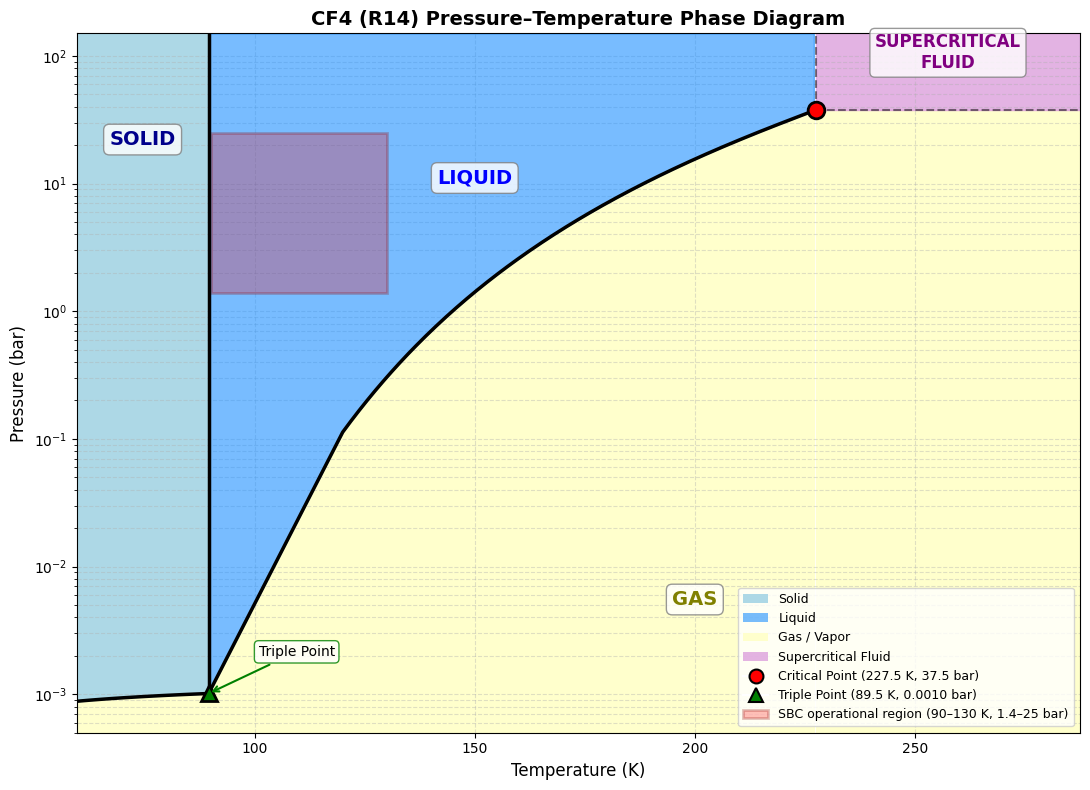

In [3]:
# --- Build complete saturation + sublimation curves for CF4 ---

# Convert to bar
CF4_T_sat_K   = np.asarray(CF4_T_sat)
CF4_P_sat_bar = CF4_P_sat / 100
CF4_P_crit_bar   = CF4_P_crit / 100
CF4_P_triple_bar = CF4_P_triple / 100

# Strip NaNs
valid = ~np.isnan(CF4_P_sat_bar)
CF4_T_sat_valid = CF4_T_sat_K[valid]
CF4_P_sat_valid = CF4_P_sat_bar[valid]

# Log-linear bridge from triple point to first valid REFPROP point
T_bridge = np.linspace(CF4_T_triple, CF4_T_sat_valid[0], 50)
log_P_bridge = np.interp(T_bridge, [CF4_T_triple, CF4_T_sat_valid[0]],
                          [np.log(CF4_P_triple_bar), np.log(CF4_P_sat_valid[0])])
P_bridge = np.exp(log_P_bridge)

CF4_T_sat_full = np.concatenate([T_bridge[:-1], CF4_T_sat_valid])
CF4_P_sat_full = np.concatenate([P_bridge[:-1], CF4_P_sat_valid])

# Approximate sublimation curve
CF4_T_min_K = CF4_T_triple - 30
CF4_T_max_K = CF4_T_crit   + 60
CF4_P_min, CF4_P_max = 0.0005, 150

T_sublim = np.linspace(CF4_T_min_K, CF4_T_triple, 100)
P_sublim = CF4_P_triple_bar * np.exp(25 * (1/CF4_T_triple - 1/T_sublim))
P_sublim = np.clip(P_sublim, CF4_P_min, CF4_P_triple_bar)

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 8))

# Fill phase regions
ax.fill_between(CF4_T_sat_full, CF4_P_min, CF4_P_sat_full,       color='#FFFFCC', alpha=1.0, zorder=1)  # Gas
ax.fill_between(T_sublim,       CF4_P_min, P_sublim,              color='#FFFFCC', alpha=1.0, zorder=1)  # Gas (below triple)
ax.fill_between([CF4_T_crit, CF4_T_max_K], CF4_P_min, CF4_P_crit_bar, color='#FFFFCC', alpha=1.0, zorder=1)  # Gas (supercrit T)
ax.fill_between(CF4_T_sat_full, CF4_P_sat_full, CF4_P_max,        color='#1E90FF', alpha=0.6, zorder=2)  # Liquid
ax.fill_between([CF4_T_crit, CF4_T_max_K], CF4_P_crit_bar, CF4_P_max, color='#DDA0DD', alpha=0.8, zorder=1)  # Supercritical
ax.fill_between(T_sublim, P_sublim, CF4_P_max,                    color='#ADD8E6', alpha=1.0, zorder=1)  # Solid

# Phase boundary lines
ax.plot(CF4_T_sat_full, CF4_P_sat_full, 'k-', lw=2.5, zorder=5)
ax.plot(T_sublim, P_sublim, 'k-', lw=2.5, zorder=5)
ax.plot([CF4_T_triple, CF4_T_triple], [CF4_P_triple_bar, CF4_P_max], 'k-', lw=2.5, zorder=5)
ax.plot([CF4_T_crit, CF4_T_max_K], [CF4_P_crit_bar, CF4_P_crit_bar], 'k--', lw=1.5, alpha=0.5, zorder=4)
ax.plot([CF4_T_crit, CF4_T_crit],  [CF4_P_crit_bar, CF4_P_max],      'k--', lw=1.5, alpha=0.5, zorder=4)

# Critical and triple points
ax.plot(CF4_T_crit,   CF4_P_crit_bar,   'ro', ms=12, mec='black', mew=2, zorder=6)
ax.plot(CF4_T_triple, CF4_P_triple_bar, 'g^', ms=12, mec='black', mew=2, zorder=6)

# SBC operational region
roi_T_min, roi_T_max = 90, 130
roi_P_min, roi_P_max = 1.4, 25
ax.add_patch(Rectangle((roi_T_min, roi_P_min), roi_T_max - roi_T_min, roi_P_max - roi_P_min,
                        lw=2, edgecolor='darkred', facecolor='red', alpha=0.25, zorder=4))

# Phase region labels
bbox = dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(CF4_T_triple - 15, 20,       'SOLID',             fontsize=14, fontweight='bold', ha='center', color='darkblue', bbox=bbox, zorder=7)
ax.text(150,               10,       'LIQUID',            fontsize=14, fontweight='bold', ha='center', color='blue',     bbox=bbox, zorder=7)
ax.text(200,               0.005,    'GAS',               fontsize=14, fontweight='bold', ha='center', color='olive',    bbox=bbox, zorder=7)
ax.text(CF4_T_crit + 30,   80,       'SUPERCRITICAL\nFLUID', fontsize=12, fontweight='bold', ha='center', color='purple', bbox=bbox, zorder=7)

# Triple point annotation
ax.annotate('Triple Point', xy=(CF4_T_triple, CF4_P_triple_bar),
            xytext=(CF4_T_triple + 20, 0.002), fontsize=10, ha='center',
            arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='green'), zorder=7)

# Legend
legend_elements = [
    Patch(facecolor='#ADD8E6', alpha=1.0, label='Solid'),
    Patch(facecolor='#1E90FF', alpha=0.6, label='Liquid'),
    Patch(facecolor='#FFFFCC', alpha=1.0, label='Gas / Vapor'),
    Patch(facecolor='#DDA0DD', alpha=0.8, label='Supercritical Fluid'),
    plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='red',   ms=10, mec='black', mew=1.5,
               label=f'Critical Point ({CF4_T_crit:.1f} K, {CF4_P_crit_bar:.1f} bar)'),
    plt.Line2D([0],[0], marker='^', color='w', markerfacecolor='green', ms=10, mec='black', mew=1.5,
               label=f'Triple Point ({CF4_T_triple:.1f} K, {CF4_P_triple_bar:.4f} bar)'),
    Patch(facecolor='red', alpha=0.25, edgecolor='darkred', lw=2,
          label=f'SBC operational region ({roi_T_min}–{roi_T_max} K, {roi_P_min}–{roi_P_max} bar)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

ax.set_xlabel('Temperature (K)', fontsize=12)
ax.set_ylabel('Pressure (bar)', fontsize=12)
ax.set_title('CF4 (R14) Pressure–Temperature Phase Diagram', fontsize=14, fontweight='bold')
ax.set_yscale('log')
ax.set_xlim([CF4_T_min_K, CF4_T_max_K])
ax.set_ylim([CF4_P_min, CF4_P_max])
ax.grid(True, which='both', ls='--', alpha=0.4, zorder=0)
plt.tight_layout()
plt.show()

---
## Part 2: Argon Seitz Bubble Nucleation Thresholds

The Seitz model gives the minimum energy deposition $Q$ required to nucleate a critical bubble in a superheated liquid. Valid only where $P < P_{\text{sat}}(T)$.

In [4]:
# --- Argon fluid setup and saturation curve ---
RP.SETUPdll(1, "ARGON", "HMX.BNC", "DEF")
ar = RP.INFOdll(1)

Ar_T_triple = ar.Ttrp
Ar_T_crit   = ar.Tc
Ar_P_crit   = ar.Pc   # kPa

Ar_T_sat = np.linspace(Ar_T_triple + 0.01, Ar_T_crit - 0.01, 300)
Ar_P_sat = np.array([
    RP.SATTdll(T, [1.0], 1).P if RP.SATTdll(T, [1.0], 1).ierr == 0 else np.nan
    for T in Ar_T_sat
])  # kPa

Ar_P_triple = RP.SATTdll(Ar_T_triple + 0.01, [1.0], 1).P  # kPa
Ar_P_sat_bar = Ar_P_sat / 100

print(f"Argon triple point:  {Ar_T_triple:.2f} K,  {Ar_P_triple/100:.5f} bar")
print(f"Argon critical point: {Ar_T_crit:.2f} K,  {Ar_P_crit/100:.2f} bar")
print(f"Saturation curve: {np.sum(~np.isnan(Ar_P_sat))} valid points")

Argon triple point:  83.81 K,  0.68970 bar
Argon critical point: 150.69 K,  48.63 bar
Saturation curve: 300 valid points


In [5]:
# --- Seitz threshold calculation over (T, P) grid ---

bar_to_psia = 14.50377

n_grid = 60
T_K_range  = np.linspace(90, 135, n_grid)
P_bar_range = np.linspace(0.5, 20, n_grid)
T_K_grid, P_bar_grid = np.meshgrid(T_K_range, P_bar_range)
Q_grid = np.full_like(T_K_grid, np.nan)

# Interpolate Argon saturation pressure onto the grid temperatures
Ar_sat_interp = interp1d(Ar_T_sat, Ar_P_sat_bar, bounds_error=False, fill_value=np.nan)
P_sat_at_T = Ar_sat_interp(T_K_range)

print(f"Grid: {n_grid}×{n_grid} = {n_grid**2} points  ({T_K_range[0]:.0f}–{T_K_range[-1]:.0f} K,  {P_bar_range[0]:.1f}–{P_bar_range[-1]:.1f} bar)")
print("Calculating Seitz Q (superheated liquid region only)...")

valid_count = 0
for i, P_bar in enumerate(P_bar_range):
    P_psia = P_bar * bar_to_psia
    for j, T_K in enumerate(T_K_range):
        if not np.isnan(P_sat_at_T[j]) and P_bar < P_sat_at_T[j]:
            try:
                result = SeitzModel(P_psia, T_K - 273.15, Fluid="ARGON")
                if result is not None and result.Q is not None:
                    Q_grid[i, j] = result.Q
                    valid_count += 1
            except Exception:
                pass
    if (i + 1) % 20 == 0:
        print(f"  {i+1}/{n_grid} rows done...")

print(f"\nDone. {valid_count} valid Q values.")
print(f"Q range: {np.nanmin(Q_grid)*1000:.1f} – {np.nanmax(Q_grid)*1000:.1f} eV")

Grid: 60×60 = 3600 points  (90–135 K,  0.5–20.0 bar)
Calculating Seitz Q (superheated liquid region only)...
  20/60 rows done...
  40/60 rows done...
  60/60 rows done...

Done. 1646 valid Q values.
Q range: 12.8 – 223031178586.4 eV


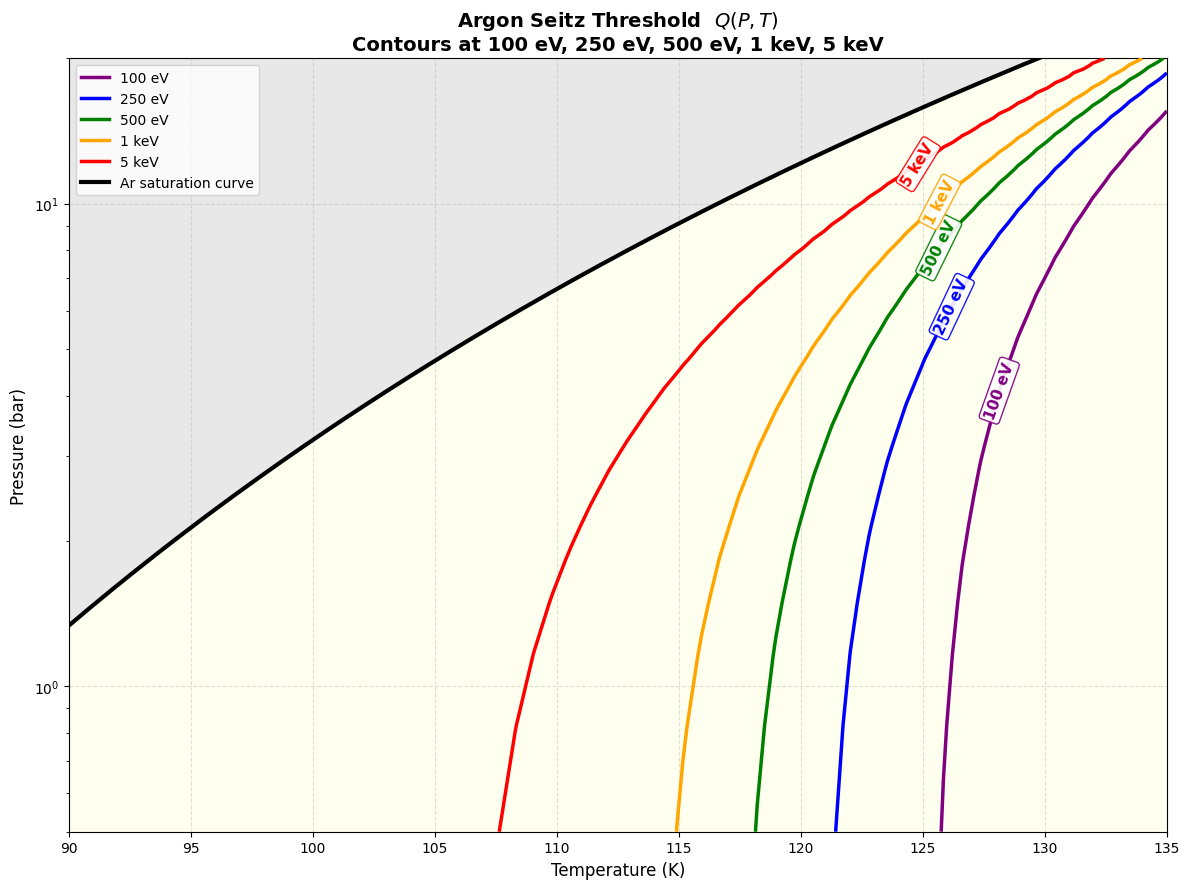

In [6]:
# --- Seitz contour plot (Argon operating space) ---

threshold_keV    = [0.1, 0.25, 0.5, 1.0, 5.0]
threshold_labels = ['100 eV', '250 eV', '500 eV', '1 keV', '5 keV']
threshold_colors = ['purple', 'blue', 'green', 'orange', 'red']
label_P_targets  = [4, 6, 8, 10, 12]  # bar – stagger labels vertically

# High-res saturation curve for display
T_sat_hires = np.linspace(90, 150, 500)
P_sat_hires = Ar_sat_interp(T_sat_hires)

fig, ax = plt.subplots(figsize=(12, 9))

ax.fill_between(T_sat_hires, P_sat_hires, 50,           color='lightgray',   alpha=0.5, label='Stable liquid ($P > P_{sat}$)', zorder=1)
ax.fill_between(T_sat_hires, 0,           P_sat_hires,  color='lightyellow', alpha=0.5, label='Superheated liquid ($P < P_{sat}$)', zorder=1)
ax.plot(T_sat_hires, P_sat_hires, 'k-', lw=3, label='Ar saturation curve', zorder=5)

ax.set_xlim([T_K_range[0], T_K_range[-1]])
ax.set_ylim([P_bar_range[0], P_bar_range[-1]])
fig.canvas.draw()  # commit axis limits so transform is correct

for level, label, color, P_target in zip(threshold_keV, threshold_labels, threshold_colors, label_P_targets):
    cs = ax.contour(T_K_grid, P_bar_grid, Q_grid, levels=[level], colors=[color], linewidths=[2.5], zorder=10)
    if cs.allsegs and cs.allsegs[0]:
        seg = cs.allsegs[0][0]
        idx = np.argmin(np.abs(seg[:, 1] - P_target))
        lx, ly = seg[idx, 0], seg[idx, 1]
        if 0 < idx < len(seg) - 1:
            d = ax.transData.transform(seg[idx+1]) - ax.transData.transform(seg[idx-1])
            angle = np.degrees(np.arctan2(d[1], d[0]))
        else:
            angle = 45
        ax.text(lx, ly, label, fontsize=11, fontweight='bold', color=color,
                ha='center', va='center', rotation=angle, rotation_mode='anchor',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor=color, alpha=0.9), zorder=15)

legend_elements = [
    plt.Line2D([0],[0], color=c, lw=2.5, label=l)
    for c, l in zip(threshold_colors, threshold_labels)
] + [plt.Line2D([0],[0], color='black', lw=3, label='Ar saturation curve')]

ax.set_xlabel('Temperature (K)', fontsize=12)
ax.set_ylabel('Pressure (bar)', fontsize=12)
ax.set_title('Argon Seitz Threshold  $Q(P,T)$\nContours at 100 eV, 250 eV, 500 eV, 1 keV, 5 keV', fontsize=14, fontweight='bold')
ax.set_yscale('log')
ax.grid(True, ls='--', alpha=0.4)
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

---
## Part 3: Overlay — Argon Seitz Thresholds on CF4 Phase Space

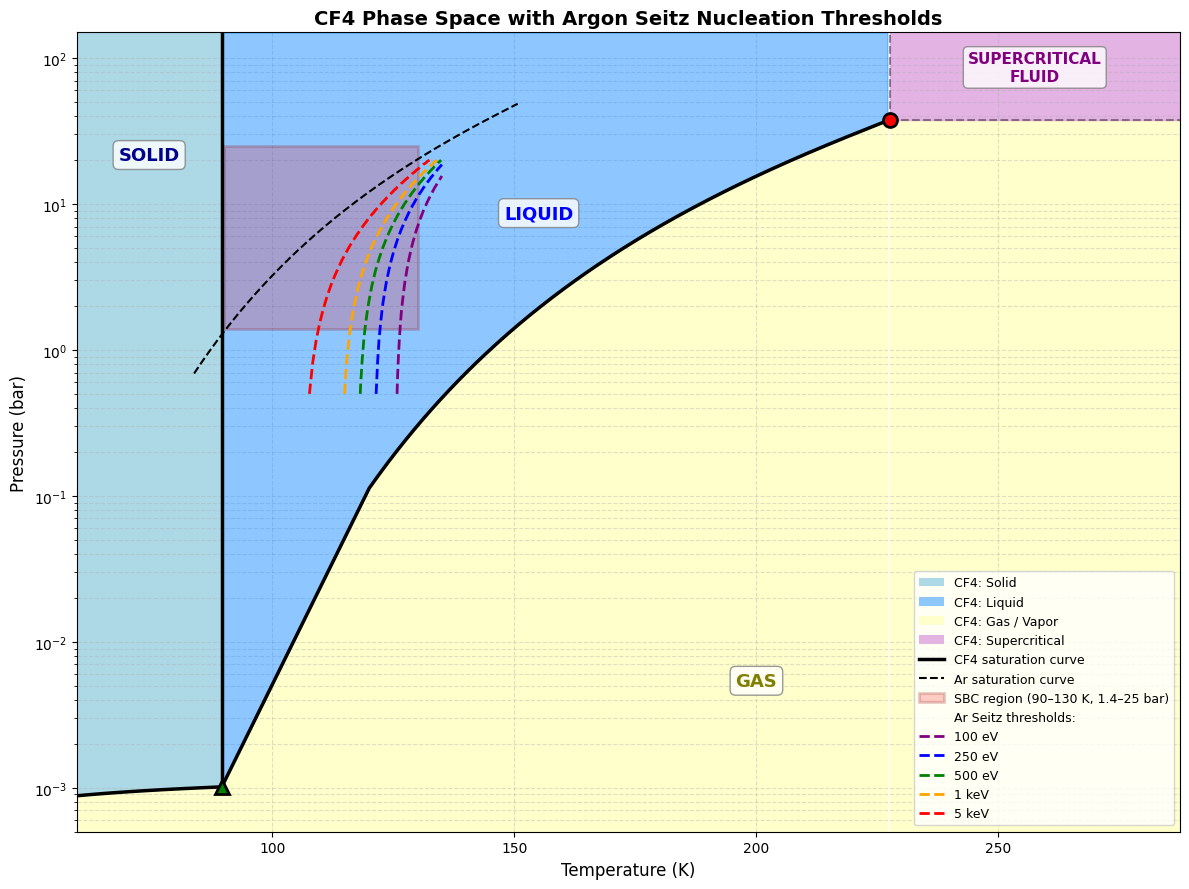

In [ ]:
# --- Overlay: CF4 phase diagram + Argon Seitz threshold contours ---

fig, ax = plt.subplots(figsize=(12, 9))

# --- CF4 phase regions (same colours as Part 1) ---
ax.fill_between(CF4_T_sat_full, CF4_P_min, CF4_P_sat_full,            color='#FFFFCC', alpha=1.0, zorder=1)
ax.fill_between(T_sublim,       CF4_P_min, P_sublim,                  color='#FFFFCC', alpha=1.0, zorder=1)
ax.fill_between([CF4_T_crit, CF4_T_max_K], CF4_P_min, CF4_P_crit_bar, color='#FFFFCC', alpha=1.0, zorder=1)
ax.fill_between(CF4_T_sat_full, CF4_P_sat_full, CF4_P_max,            color='#1E90FF', alpha=0.5, zorder=2)
ax.fill_between([CF4_T_crit, CF4_T_max_K], CF4_P_crit_bar, CF4_P_max, color='#DDA0DD', alpha=0.8, zorder=1)
ax.fill_between(T_sublim, P_sublim, CF4_P_max,                        color='#ADD8E6', alpha=1.0, zorder=1)

# CF4 phase boundary lines (thick solid, matching Part 1)
ax.plot(CF4_T_sat_full, CF4_P_sat_full, 'k-', lw=2.5, zorder=5, label='CF4 saturation curve')
ax.plot(T_sublim, P_sublim, 'k-', lw=2.5, zorder=5)
ax.plot([CF4_T_triple, CF4_T_triple], [CF4_P_triple_bar, CF4_P_max], 'k-', lw=2.5, zorder=5)
ax.plot([CF4_T_crit, CF4_T_max_K], [CF4_P_crit_bar, CF4_P_crit_bar], 'k--', lw=1.5, alpha=0.4, zorder=4)
ax.plot([CF4_T_crit, CF4_T_crit],  [CF4_P_crit_bar, CF4_P_max],      'k--', lw=1.5, alpha=0.4, zorder=4)

# CF4 special points
ax.plot(CF4_T_crit,   CF4_P_crit_bar,   'ro', ms=10, mec='black', mew=2, zorder=6)
ax.plot(CF4_T_triple, CF4_P_triple_bar, 'g^', ms=10, mec='black', mew=2, zorder=6)

# SBC operational region
ax.add_patch(Rectangle((roi_T_min, roi_P_min), roi_T_max - roi_T_min, roi_P_max - roi_P_min,
                        lw=2, edgecolor='darkred', facecolor='red', alpha=0.2, zorder=3))

# Phase region labels
bbox = dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(CF4_T_triple - 15, 20,    'SOLID',             fontsize=13, fontweight='bold', ha='center', color='darkblue', bbox=bbox, zorder=7)
ax.text(155,               8,     'LIQUID',            fontsize=13, fontweight='bold', ha='center', color='blue',     bbox=bbox, zorder=7)
ax.text(200,               0.005, 'GAS',               fontsize=13, fontweight='bold', ha='center', color='olive',    bbox=bbox, zorder=7)
ax.text(CF4_T_crit + 30,   70,    'SUPERCRITICAL\nFLUID', fontsize=11, fontweight='bold', ha='center', color='purple', bbox=bbox, zorder=7)

# --- Argon saturation curve ---
Ar_P_sat_bar_full = Ar_P_sat / 100
Ar_valid = ~np.isnan(Ar_P_sat_bar_full)
ax.plot(Ar_T_sat[Ar_valid], Ar_P_sat_bar_full[Ar_valid], 'k--', lw=1.5, zorder=6, label='Ar saturation curve')

# --- Argon Seitz threshold contours (dashed, no inline labels) ---
for level, color in zip(threshold_keV, threshold_colors):
    ax.contour(T_K_grid, P_bar_grid, Q_grid, levels=[level],
               colors=[color], linewidths=[2.0], linestyles=['--'], zorder=10)

# --- Legend ---
legend_elements = [
    Patch(facecolor='#ADD8E6', alpha=1.0, label='CF4: Solid'),
    Patch(facecolor='#1E90FF', alpha=0.5, label='CF4: Liquid'),
    Patch(facecolor='#FFFFCC', alpha=1.0, label='CF4: Gas / Vapor'),
    Patch(facecolor='#DDA0DD', alpha=0.8, label='CF4: Supercritical'),
    plt.Line2D([0],[0], color='black', lw=2.5, ls='-',  label='CF4 saturation curve'),
    plt.Line2D([0],[0], color='black', lw=1.5, ls='--', label='Ar saturation curve'),
    Patch(facecolor='red', alpha=0.2, edgecolor='darkred', lw=2,
          label=f'SBC region ({roi_T_min}–{roi_T_max} K, {roi_P_min}–{roi_P_max} bar)'),
    plt.Line2D([0],[0], color='w', lw=0, label='Ar Seitz thresholds:'),
] + [
    plt.Line2D([0],[0], color=c, lw=2.0, ls='--', label=l)
    for c, l in zip(threshold_colors, threshold_labels)
]

ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
ax.set_xlabel('Temperature (K)', fontsize=12)
ax.set_ylabel('Pressure (bar)', fontsize=12)
ax.set_title('CF4 Phase Space with Argon Seitz Nucleation Thresholds', fontsize=14, fontweight='bold')
ax.set_yscale('log')
ax.set_xlim([CF4_T_min_K, CF4_T_max_K])
ax.set_ylim([CF4_P_min, CF4_P_max])
ax.grid(True, which='both', ls='--', alpha=0.4, zorder=0)
plt.tight_layout()
plt.show()